# Analiza sieciowa swipe'ów: (c) Hierarchia pożądania i ligi

**Pytanie badawcze:** Czy na swipe'ach widać strukturę hierarchiczną ('ligi pożądania')
w myśl modelu Brucha i Newmana (2018)? Czy szansa odpowiedzi maleje z różnicą lig?

**Miara pożądania $D(u)$:** cross-fitted efekt odbiorcy z M1 w percentylach (0–100%).
**Analiza lig:**
1. Krzywa $P(\text{prawy swipe} \mid \text{różnica pożądania})$ dla krawędzi.
2. Krzywa wzajemności warunkowej $P(B\to A \mid A\to B, \text{różnica lig})$.

In [1]:
import json

import matplotlib.pyplot as plt
from PIL import Image

from rentfriends.graph.data import verify_h1_sha256

verify_h1_sha256()
with open("../reports/graph/numbers.json") as f:
    numbers = json.load(f)

res_c = numbers["results_c"]
n_rec = res_c["n_receivers_with_desire_score"]
pct_mean = res_c["desire_pct_mean"]
print(f"Liczba sklasyfikowanych odbiorców: {n_rec:,}")
print(f"Średni percentyl pożądania: {pct_mean:.1f}%")

Liczba sklasyfikowanych odbiorców: 1,354
Średni percentyl pożądania: 50.0%


## 1. P(prawy swipe) w funkcji różnicy pożądania

Różnica rang = percentyl pożądania odbiorcy minus percentyl nadawcy.
Koszowanie na percentyle z minimalną licznością kosza $\ge 100$ par.

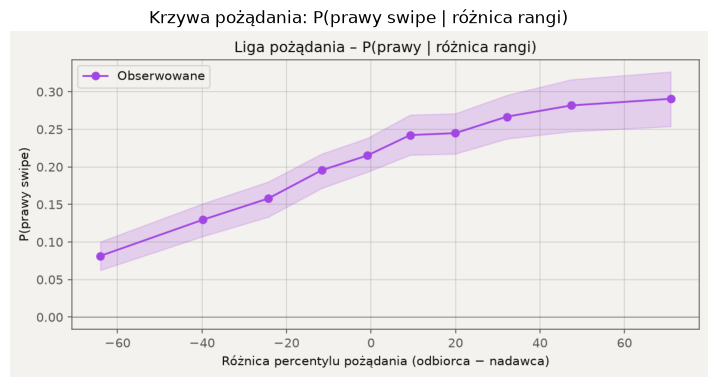

In [2]:
img_p_right = Image.open("../reports/graph/fig_league_p_right.png")
plt.figure(figsize=(9, 5))
plt.imshow(img_p_right)
plt.axis("off")
plt.title("Krzywa pożądania: P(prawy swipe | różnica rangi)", fontsize=12)
plt.show()

## 2. Wzajemność warunkowa: P(B→A prawo | A→B prawo)

Sprawdzamy hipotezę 'aspiration gap': czy szansa, że B odwzajemni lajka A,
maleje gdy B zajmuje znacznie wyższą pozycję w hierarchii niż A?

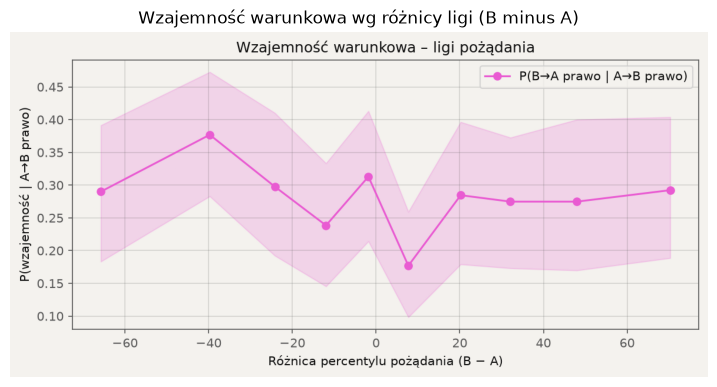

In [3]:
img_recip = Image.open("../reports/graph/fig_league_reciprocate.png")
plt.figure(figsize=(9, 5))
plt.imshow(img_recip)
plt.axis("off")
plt.title("Wzajemność warunkowa wg różnicy ligi (B minus A)", fontsize=12)
plt.show()

## 3. Kluczowe wnioski

1. **Silna hierarchia akceptacji**: Profile z wyższym pożądaniem otrzymują znacznie
więcej prawych swipe'ów, niezależnie od pozycji nadawcy.
2. **Wynik negatywny dla hipotezy aspiration gap we wzajemności**: Chociaż nadawcy chętniej wysyłają lajki osobom z wyższych lig, szansa na odwzajemnienie polubienia w parach z obustronną ekspozycją pozostaje płaska (~28%) i nie spada wraz z różnicą lig.
3. **Zastrzeżenie (G1)**: Wynik dotyczy wyłącznie par z obustronną ekspozycją.